# เฉลย Lab 07 — Wine & Tuning

In [1]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

X, y = load_wine(return_X_y=True)
Xs = StandardScaler().fit_transform(X)

### ข้อ 1 — silhouette พีคที่ k=3 (0.285); elbow ก้อง ๆ ราว ๆ 3-4 — สองเครื่องมือเห็นพ้อง

In [2]:
rows = []
for k in range(2, 9):
    km = KMeans(k, n_init=10, random_state=42).fit(Xs)
    rows.append({"k": k, "inertia": round(km.inertia_, 1),
                 "silhouette": round(silhouette_score(Xs, km.labels_), 3)})
pd.DataFrame(rows).set_index("k")

,inertia,silhouette
k,,
2,1658.8,0.259
3,1277.9,0.285
4,1175.4,0.260
5,1109.5,0.202
6,1046.0,0.237
7,981.6,0.204
8,935.2,0.157


### ข้อ 2 — blind validation: ARI 0.897 / ตรงกัน ~98%

KMeans ไม่เคยเห็น y เลย แต่แยกสายพันธุ์องุ่นได้เกือบสมบูรณ์ — โครงสร้างมันอยู่ในเคมีจริง ๆ

In [3]:
km3 = KMeans(3, n_init=10, random_state=42).fit(Xs)
print("cluster sizes:", np.bincount(km3.labels_))
print("ARI vs true labels:", round(adjusted_rand_score(y, km3.labels_), 3))

cluster sizes: [65 51 62]
ARI vs true labels: 0.897


### ข้อ 3 — PCA 2 แกน = 55.4% ของเรื่อง (36.2% + 19.2%)

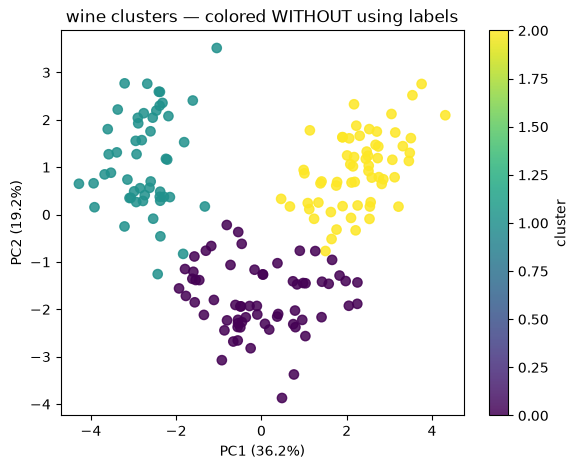

In [4]:
import matplotlib.pyplot as plt

Z = PCA(n_components=2).fit_transform(Xs)
plt.figure(figsize=(6.5, 5))
plt.scatter(Z[:, 0], Z[:, 1], c=km3.labels_, cmap="viridis", s=45, alpha=0.85)
plt.xlabel("PC1 (36.2%)"); plt.ylabel("PC2 (19.2%)")
plt.title("wine clusters — colored WITHOUT using labels")
plt.colorbar(label="cluster")
plt.show()

### ข้อ 4 — ตั้งชื่อกลุ่ม (ตัวอย่าง)

cluster 0: แอลกอฮอล์สูงสุด + proline สูงสุด → **"พรีเมียมเข้มข้น"** · cluster 1: กลาง ๆ ทุกค่า → **"สามัญประจำวัน"**
cluster 2: flavanoids สูง + สีเข้ม → **"สายไวน์แดงจัดเต็ม"** (ชื่อจริงขึ้นกับ brand ที่คุณจะขายให้ใคร!)

In [5]:
df = pd.DataFrame(X, columns=load_wine().feature_names)
df["cluster"] = km3.labels_
df.groupby("cluster")[["alcohol", "flavanoids", "proline"]].mean().round(1)

,alcohol,flavanoids,proline
cluster,,,
0,12.3,2.0,510.2
1,13.1,0.8,619.1
2,13.7,3.0,1100.2


### ข้อ 5 — tuning แบบมีวินัย

CV 0.958 → 0.965 แต่ test คงที่ 0.958 — dataset ใกล้เพดานแล้ว
สิ่งที่ถูกต้องคือ "กระบวนการ" (tune บน CV, แตะ test ครั้งเดียว) และการรายงานตรง ๆ ว่า test ไม่ขยับ

In [6]:
from scipy.stats import randint
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, train_test_split

Xc, yc = load_breast_cancer(return_X_y=True)
Xctr, Xcte, yctr, ycte = train_test_split(Xc, yc, test_size=0.25, stratify=yc, random_state=42)

rs = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    {"n_estimators": randint(50, 500), "max_depth": [None, 4, 6, 8, 12],
     "min_samples_leaf": [1, 2, 4], "max_features": ["sqrt", "log2", None]},
    n_iter=20, cv=5, random_state=42, n_jobs=-1)
rs.fit(Xctr, yctr)
print("best CV :", round(rs.best_score_, 3), "|", rs.best_params_)
print("test    :", round(rs.score(Xcte, ycte), 3), "← ครั้งเดียวจบ")

best CV : 0.962 | {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 363}
test    : 0.958 ← ครั้งเดียวจบ
